Prediction of Customer Churn by Means of Machine Learning

Introduction

The aim of the current research is to predict customer churn in a telecom company on the basis of the information related to customer and services.

Python, Pandas, Matplotlib, Seaborn, and Scikit-learn were used for the data exploration, preprocessing, training of a Logistic Regression model, and evaluation of its performance.

The impact of class balancing on the prediction of customers who might churn is considered in this project as well.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
df = pd.read_csv('/content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [24]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [25]:
df.shape

(7043, 21)

In [20]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [28]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [29]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


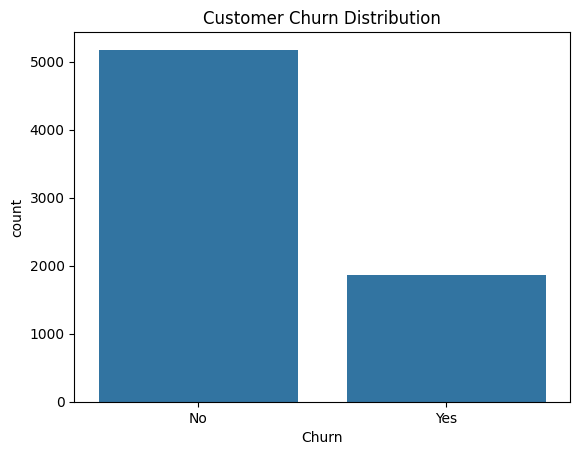

In [30]:
sns.countplot(x='Churn', data=df)
plt.title('Customer Churn Distribution')
plt.show()

In [31]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


In [32]:
pd.crosstab(df['Contract'],df['Churn'])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


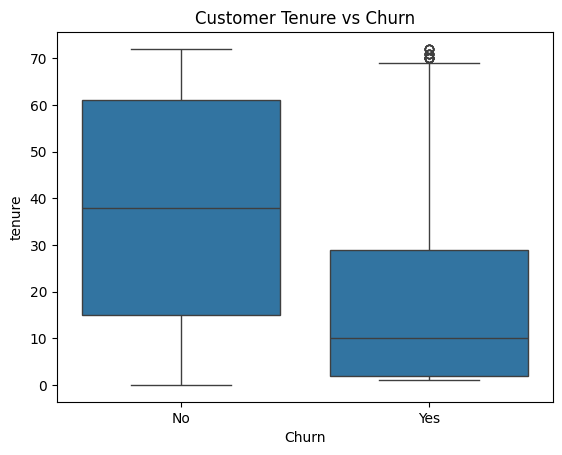

In [33]:
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title('Customer Tenure vs Churn')
plt.show()

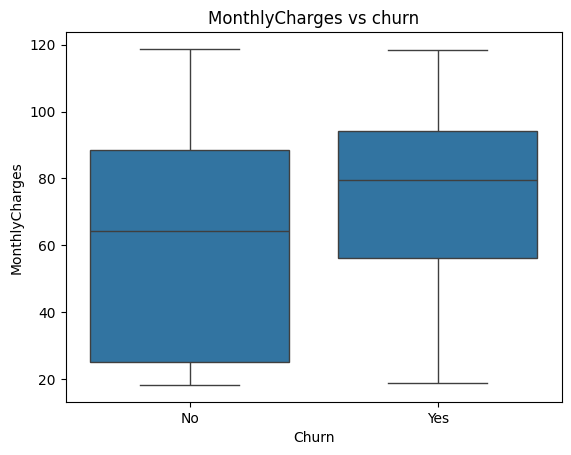

In [34]:
sns.boxplot(x='Churn',y='MonthlyCharges',data=df)
plt.title('MonthlyCharges vs churn')
plt.show()

In [35]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [36]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


pd.to_numeric() converts text values into numbers.

errors='coerce' converts any invalid values into NaN instead of crashing.

In [37]:
df['TotalCharges'].dtype

dtype('float64')

In [38]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [39]:
df = df.dropna(subset=['TotalCharges'])

dropna() removes rows containing missing values.



subset=['TotalCharges'] means we remove rows only when TotalCharges is missing.

In [40]:
df.isnull().sum().sum()

np.int64(0)

In [41]:
y = df['Churn']
X = df.drop('Churn', axis=1)

In [42]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (7032, 20)
Target: (7032,)


In [43]:
X.select_dtypes(include='object').columns

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

In [44]:
X = X.drop('customerID', axis=1)

In [46]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [47]:
print(X.shape)

(7032, 30)


In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [49]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5625, 30)
X_test: (1407, 30)
y_train: (5625,)
y_test: (1407,)


In [79]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [80]:
y_pred = model.predict(X_test)

In [81]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 73.13432835820896 %


In [82]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.90      0.71      0.80      1033
         Yes       0.50      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.75      1407



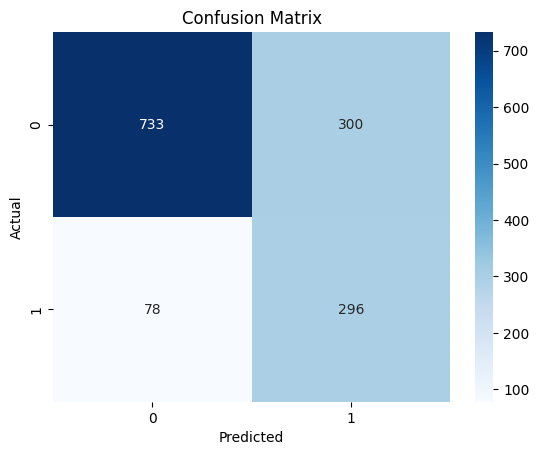

In [83]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [84]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.90      0.71      0.80      1033
         Yes       0.50      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.75      1407



Conclusion

In this project, I created a Customer Churn Prediction model using Logistic Regression in Python.

Firstly, I analyzed the dataset, filled in missing values, one-hot encoded categorical features, and created a train-test split. Then, I trained a Logistic Regression model, and used metrics such as accuracy, precision, recall, F1-score, and the confusion matrix for evaluation purposes.

Overall, the unbalanced model gave a prediction accuracy of about 79%, whereas the balanced model provided an accuracy of 73%. However, the balanced model increased the recall of churn customers from 52% to 79%.

It shows that the trade-off between accuracy and detecting at-risk customers exists. The model might be useful for a company to find out their potential churners and develop appropriate strategies.